# Minimum example for end-to-end learning with pypsps and PyTorch (with Kang-Schafer)

This is the PyTorch version of `pypsps_minimal_working_example.ipynb`. It uses the native `pypsps.torch` backend, so it needs only `pip install "pypsps[torch] @ git+https://github.com/gmgeorg/pypsps.git"` (plus `seaborn` and `matplotlib` for the plots) and runs without TensorFlow.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import pypsps
import pypsps.datasets
import pypsps.torch.models
import pypsps.torch.presets
import pypsps.torch.training
import pypsps.torch.callbacks
import pypsps.torch.families
from pypsps.torch.mixture import StateMixture
import pypsps.inference

# Simulating data

In [4]:
ks_sampler = pypsps.datasets.KangSchafer(true_ate=20, seed=123)
ks_data = ks_sampler.sample(n_samples=1000)
ks_data.to_data_frame().head()

,outcome,treatment,z1,z2,z3,z4,x1,x2,x3,x4,propensity_score
0,195.861788,1,-1.085631,0.997345,0.282978,-1.506295,0.581110,10.745574,0.202998,379.901059,0.840799
1,195.488662,1,-0.578600,1.651437,-2.426679,-0.428913,0.748787,11.058150,0.282511,450.395521,0.886339
2,222.810098,0,1.265936,-0.866740,-0.678886,-0.094709,1.883192,9.809357,0.180959,362.466410,0.179445
3,229.073054,0,1.491390,-0.638902,-0.443982,-0.434351,2.107906,9.882625,0.188639,358.221742,0.160244
4,318.044041,0,2.205930,2.186786,1.004054,0.386186,3.013087,10.216971,0.326506,509.539087,0.197472


In [5]:
# Naive ATE
ks_data.naive_ate()

np.float64(0.5877855068033)

# Building a PSPS model for binary treatment and continuous outcome

In [6]:
torch.manual_seed(10)
preset = pypsps.torch.presets.toy(
    n_states=4, n_features=ks_data.n_features,
    alpha=1.,
    learning_rate=0.02,
    df_penalty_l2=0.001,
)
# A PyTorch model is built by `build_model`; alpha, learning rate etc. are arguments of `fit` (preset.fit_kwargs).
model = pypsps.torch.models.build_model(**preset)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

PSPSModel(
  architecture='shared_trunk', n_states=4, n_features=4
  (features_bn): BatchNorm1d(4, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (predictive_state_dense_0): Dense(
    in_features=4, out_features=10, bias=True
    (activation): ReLU()
  )
  (predictive_state_dropout_0): Dropout(p=0.2, inplace=False)
  (predictive_state_bn_0): BatchNorm1d(10, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (predictive_state_dense_1): Dense(
    in_features=10, out_features=10, bias=True
    (activation): SELU()
  )
  (predictive_state_dropout_1): Dropout(p=0.2, inplace=False)
  (predictive_state_bn_1): BatchNorm1d(10, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (state_weights): PredictiveStateSimplex(
    n_states=4, in_features=14
    (linear): Linear(in_features=14, out_features=4, bias=True)
  )
  (treatment_params): PredictiveStateParams(
    n_states=4, n_columns=1
    (_activation_module

In [7]:
model.propensity_state_conditional_means().detach().numpy()

array([[0.5],
       [0.5],
       [0.5],
       [0.5]], dtype=float32)

## Training model

In [8]:
features = ks_data.features.values
treatment = ks_data.treatments.values
outcome = ks_data.outcomes.values

history = pypsps.torch.training.fit(
    model,
    features,
    treatment,
    outcome,
    epochs=250,
    batch_size=64,
    verbose=0,
    validation_split=0.2,
    callbacks=pypsps.torch.callbacks.get_default_callbacks(monitor="val_loss", patience=20),  # use "val_causal_loss_metric" for full example (see pypsps_demo.ipynb)
    **preset.fit_kwargs,  # alpha, learning rate, clipnorm, state regularizer
)
print("Epochs run:", len(history.epoch))

Epochs run: 220


## Model convergence evaluation

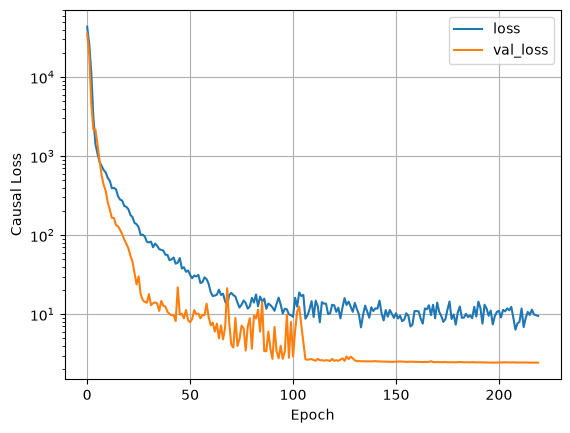

In [9]:
pd.DataFrame(history.history)[["loss", "val_loss"]].plot(logy=True)
plt.xlabel("Epoch")
plt.ylabel("Causal Loss")
plt.grid()

In [10]:
pd.DataFrame(history.history)

,loss,causal_loss_metric,outcome_nll_metric,predictive_state_df,uniform_entropy,propensity_score_binary_crossentropy,propensity_score_auroc,propensity_score_aupr,outcome_mean_squared_error,val_loss,val_causal_loss_metric,val_outcome_nll_metric,val_predictive_state_df,val_uniform_entropy,val_propensity_score_binary_crossentropy,val_propensity_score_auroc,val_propensity_score_aupr,val_outcome_mean_squared_error,learning_rate
0,43409.138281,43408.633622,43407.944301,1.320034,1.180999,0.689389,0.613958,0.631007,48400.523330,35481.053828,35480.564175,35479.895850,1.644630,0.595529,0.668293,0.782517,0.768063,47285.880981,0.02000
1,26223.256406,26222.789391,26222.132259,1.812125,0.487704,0.657117,0.705696,0.686520,39716.038079,19033.026172,19032.577266,19031.945645,1.728280,0.163753,0.631663,0.788187,0.792262,33901.607759,0.02000
2,11406.151680,11405.707737,11405.066005,1.891093,0.178892,0.641749,0.689085,0.695918,21873.946611,4695.618516,4695.193160,4694.578012,1.896360,0.113029,0.615154,0.786833,0.796009,11777.362480,0.02000
3,3143.217705,3142.779580,3142.125223,1.903115,0.112507,0.654358,0.685124,0.683313,7158.734125,2171.860596,2171.439326,2170.810394,1.973576,0.050890,0.628933,0.775492,0.789412,6259.054379,0.02000
4,1429.697224,1429.274933,1428.622253,1.926464,0.075439,0.652680,0.658285,0.681939,3483.438319,2175.122441,2174.713228,2174.080999,1.945021,0.065055,0.632242,0.769370,0.787921,5649.601269,0.02000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,9.790083,9.790059,9.129273,1.149021,0.225201,0.660786,0.720864,0.726200,32.566895,2.446673,2.446651,1.794053,1.126811,0.283011,0.652598,0.775191,0.769819,3.859278,0.00016
216,11.433683,11.433657,10.772371,1.153031,0.226450,0.661286,0.714162,0.719460,40.826875,2.445162,2.445139,1.792978,1.127965,0.285019,0.652161,0.775090,0.769776,3.886809,0.00016
217,9.965679,9.965652,9.304233,1.160300,0.227613,0.661419,0.708092,0.716687,34.092059,2.448561,2.448537,1.797096,1.130228,0.287730,0.651441,0.774990,0.769607,3.983031,0.00016
218,9.723155,9.723127,9.060695,1.157703,0.228038,0.662432,0.703440,0.708533,31.348145,2.444368,2.444344,1.792459,1.128873,0.285920,0.651885,0.774990,0.769607,3.907023,0.00016


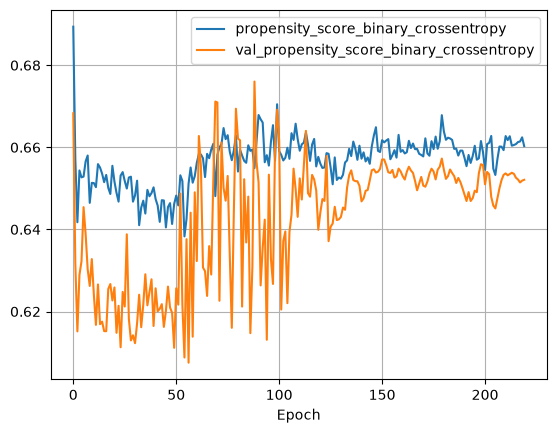

In [11]:
pd.DataFrame(history.history)[["propensity_score_binary_crossentropy", "val_propensity_score_binary_crossentropy"]].plot()
plt.xlabel("Epoch")
plt.grid()

In [12]:
model.propensity_state_conditional_means().detach().numpy()

array([[0.9705942 ],
       [0.5330878 ],
       [0.45525685],
       [0.4908125 ]], dtype=float32)

## Causal predictions & inference

In [13]:
mix = StateMixture.from_model(model)

preds = pypsps.torch.training.predict(model, features, treatment)
parts = model.layout.decode_pred(preds)
weights = parts.state_weights

propensity_score = mix.treatment_mean(torch.as_tensor(preds)).numpy()

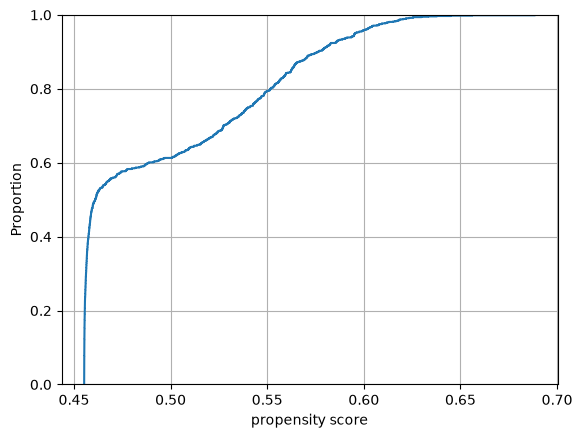

In [14]:
sns.ecdfplot(pd.Series(propensity_score.ravel()))
plt.xlabel("propensity score")
plt.grid()

<Axes: >

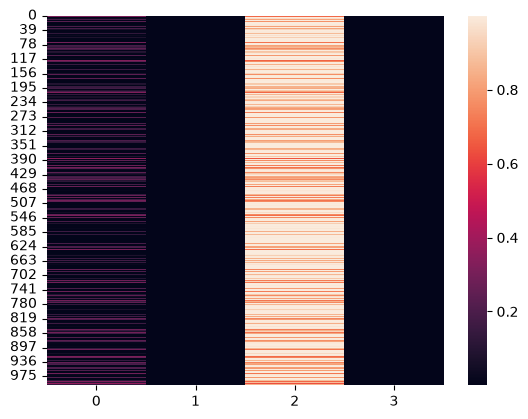

In [15]:
sns.heatmap(weights)

In [16]:
pred_ate = pypsps.inference.predict_ate_binary(model, ks_data.features)
print("True ATE: %f; predicted ATE: %f" % (ks_data.true_ate, pred_ate))

True ATE: 20.000000; predicted ATE: 18.291555


## Appendix (debug)

In [17]:
# negative log-likelihood of the first 10 outcomes under the loc and scale of state 0
pypsps.torch.families.negloglik_normal(
    torch.as_tensor(np.array(outcome[:10, 0])),
    torch.as_tensor(np.array(parts.outcome["loc"][:10, 0])),
    torch.as_tensor(np.array(parts.outcome["scale"][:10, 0])),
)

tensor([1.1980e+01, 4.6798e+00, 3.5382e+03, 3.8307e+03, 5.8232e+03, 3.3888e+03,
        1.2598e+02, 1.9976e+02, 1.2263e+02, 1.1281e+03], dtype=torch.float64)